In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
import networkx as nx
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
warnings.filterwarnings("ignore")


IEEE_CIS

In [2]:
BASE_PATH = "./data"   # <-- put your dataset folder path here

# Auto-built sub-paths (don't touch these, they just join BASE_PATH)
IEEE_TXN_PATH      = f"{BASE_PATH}/ieee_cis/train_transaction.csv"
IEEE_IDENTITY_PATH = f"{BASE_PATH}/ieee_cis/train_identity.csv"

ELLIPTIC_FEATURES_PATH = f"{BASE_PATH}/elliptic/elliptic_txs_features.csv"
ELLIPTIC_CLASSES_PATH  = f"{BASE_PATH}/elliptic/elliptic_txs_classes.csv"
ELLIPTIC_EDGES_PATH    = f"{BASE_PATH}/elliptic/elliptic_txs_edgelist.csv"



load dataset

In [3]:
base_path = r"C:\Users\gkusa\Desktop\projects\cs\Adversarial Transaction Disguise Detector\data\ieee_cis"

train_txn = pd.read_csv(base_path + r"\train_transaction.csv")
print(train_txn.shape)
train_id  = pd.read_csv(base_path + r"\train_identity.csv")
print(train_id.shape)


(590540, 394)
(144233, 41)


mergining datasets

In [4]:
ieee_df = train_txn.merge(train_id, on="TransactionID", how="left")
print("Merged shape:", ieee_df.shape)
print("Fraud rate:", round(ieee_df["isFraud"].mean() * 100, 2), "%")

# --- Memory Optimization added to avoid MemoryError later ---
import gc
import numpy as np

# Delete raw source dataframes to free up ~1.6 GB RAM immediately
del train_txn
del train_id
gc.collect()

# Downcast numerical columns to smaller numeric types
def reduce_mem_usage(df):
    for col in df.columns:
        col_type = df[col].dtype
        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                else:
                    df[col] = df[col].astype(np.int64)  
            else:
                if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
    return df

ieee_df = reduce_mem_usage(ieee_df)
gc.collect()


Merged shape: (590540, 434)
Fraud rate: 3.5 %


0

data information

In [5]:
print(ieee_df.shape)

ieee_df.info()

ieee_df.head()

(590540, 434)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float32(399), int16(1), int32(2), int8(1), object(31)
memory usage: 1.0+ GB


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


<Axes: xlabel='isFraud', ylabel='count'>

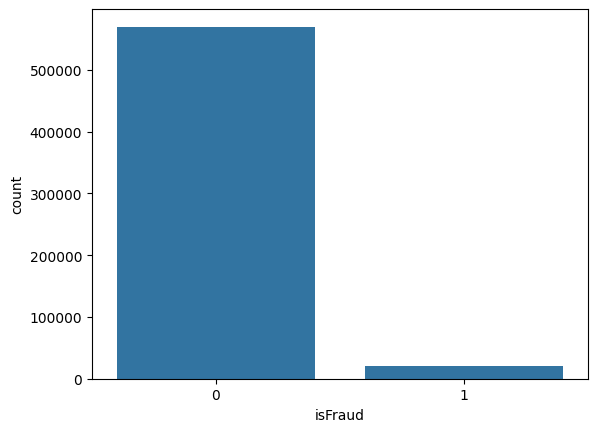

In [6]:
ieee_df["isFraud"].value_counts()
ieee_df["isFraud"].value_counts(normalize=True)*100
sns.countplot(x="isFraud",data=ieee_df)

check null values

In [7]:
ieee_df.isnull().sum()


TransactionID          0
isFraud                0
TransactionDT          0
TransactionAmt         0
ProductCD              0
                   ...  
id_36             449555
id_37             449555
id_38             449555
DeviceType        449730
DeviceInfo        471874
Length: 434, dtype: int64

plot missing columns

<Axes: >

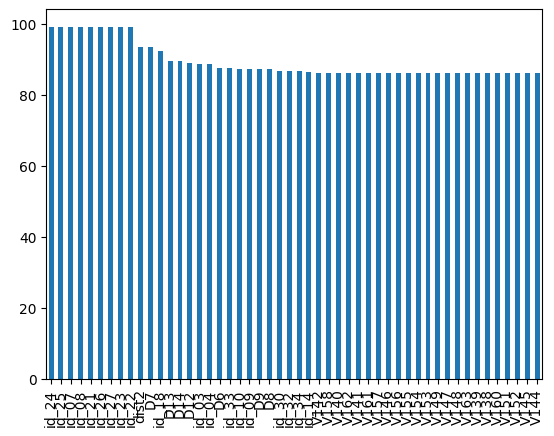

In [8]:
missing = ieee_df.isnull().sum()
missing_pct = (
    ieee_df.isnull().mean()*100
).sort_values(ascending=False)
missing_pct.head(50).plot.bar()

ploting crosstab

In [9]:
ieee_df["DeviceInfo_missing"] = (ieee_df["DeviceInfo"].isnull().astype(int))
pd.crosstab(ieee_df["DeviceInfo_missing"],ieee_df["isFraud"])




isFraud,0,1
DeviceInfo_missing,,
0,110059,8607
1,459818,12056


Distribution

<Axes: xlabel='TransactionAmt', ylabel='Count'>

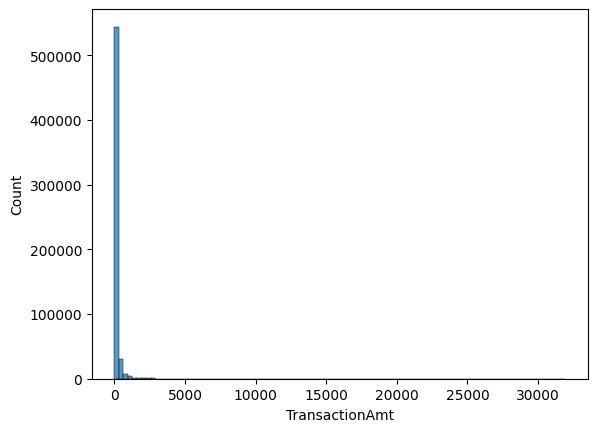

In [10]:
sns.histplot(ieee_df["TransactionAmt"],bins=100)

Fraud vs Non-Fraud Amount

<Axes: xlabel='isFraud', ylabel='TransactionAmt'>

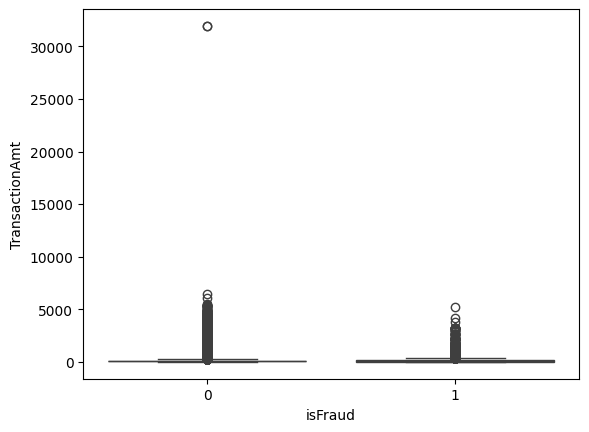

In [11]:
sns.boxplot(x="isFraud",y="TransactionAmt",data=ieee_df)

<Axes: xlabel='isFraud', ylabel='TransactionAmt'>

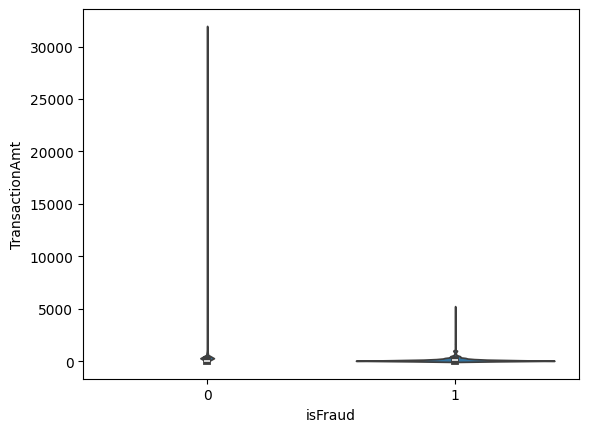

In [12]:
sns.violinplot(x="isFraud",y="TransactionAmt",data=ieee_df)

In [13]:
ieee_df["TransactionDT"].describe()

count    5.905400e+05
mean     7.372311e+06
std      4.617224e+06
min      8.640000e+04
25%      3.027058e+06
50%      7.306528e+06
75%      1.124662e+07
max      1.581113e+07
Name: TransactionDT, dtype: float64

In [14]:
ieee_df["Day"] = (ieee_df["TransactionDT"] //(24*60*60))


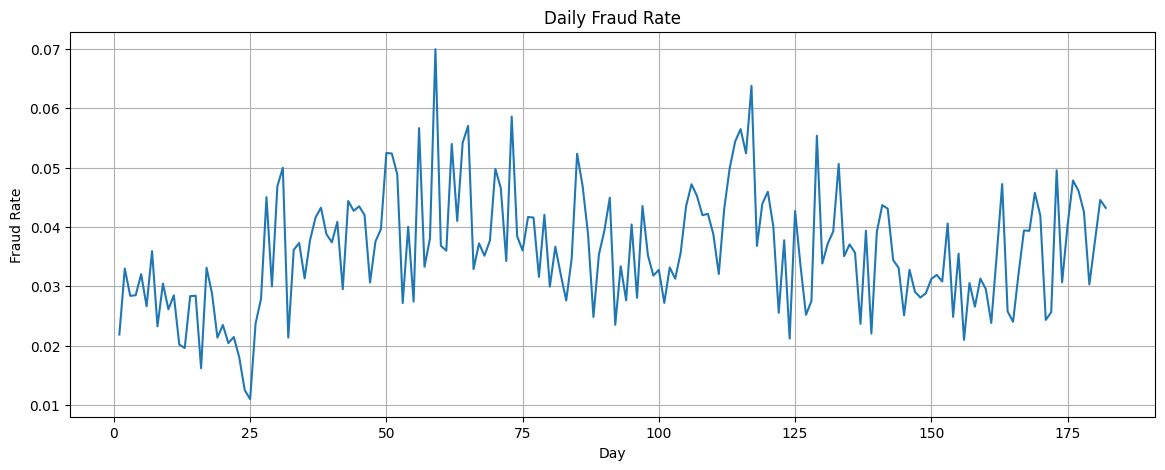

In [15]:
fraud_daily = (
    ieee_df.groupby("Day")["isFraud"]
    .mean()
)

plt.figure(figsize=(14,5))
fraud_daily.plot()
plt.title("Daily Fraud Rate")
plt.xlabel("Day")
plt.ylabel("Fraud Rate")
plt.grid(True)
plt.show()

Log Transaction Amount

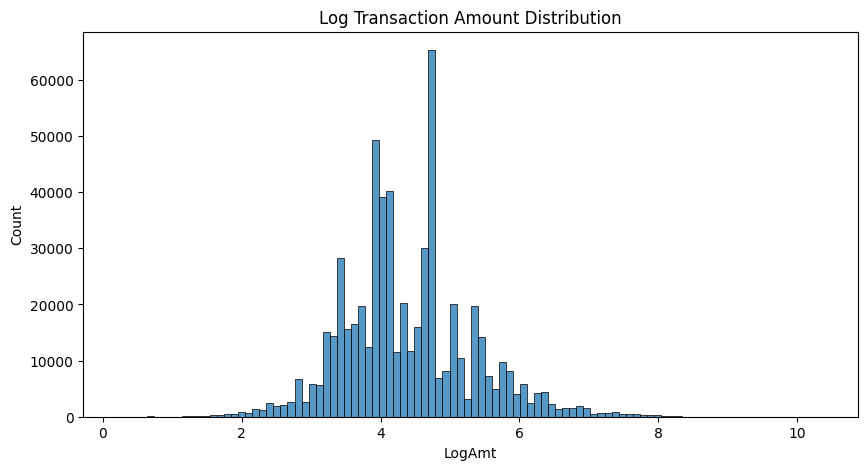

In [16]:
ieee_df["LogAmt"] = np.log1p(
    ieee_df["TransactionAmt"]
)

plt.figure(figsize=(10,5))
sns.histplot(
    ieee_df["LogAmt"],
    bins=100
)
plt.title("Log Transaction Amount Distribution")
plt.show()

ProductCD Analysis


In [17]:
pd.crosstab(ieee_df["ProductCD"],ieee_df["isFraud"])

isFraud,0,1
ProductCD,,
C,60511,8008
H,31450,1574
R,36273,1426
S,10942,686
W,430701,8969


Card Features

In [18]:
pd.crosstab(ieee_df["card4"],ieee_df["isFraud"],normalize="index")

isFraud,0,1
card4,,
american express,0.971302,0.028698
discover,0.922718,0.077282
mastercard,0.965669,0.034331
visa,0.965244,0.034756


In [19]:
pd.crosstab(ieee_df["DeviceType"],ieee_df["isFraud"],normalize="index")


isFraud,0,1
DeviceType,,
desktop,0.934785,0.065215
mobile,0.898338,0.101662


Proper Device Analysis

In [20]:
device_stats = (
    ieee_df.groupby("DeviceInfo")
    .agg(
        fraud_rate=("isFraud","mean"),
        count=("isFraud","size")
    )
)

device_stats = device_stats[
    device_stats["count"] > 100
]

device_stats.sort_values(
    "fraud_rate",
    ascending=False
).head(20)

,fraud_rate,count
DeviceInfo,,
hi6210sft Build/MRA58K,0.947368,190
SM-A300H Build/LRX22G,0.832512,203
SM-J320M Build/LMY47V,0.333333,171
WAS-LX3 Build/HUAWEIWAS-LX3,0.259259,108
Moto Z2 Play Build/NPSS26.118-19-14,0.232558,129
Moto E (4) Plus Build/NMA26.42-69,0.200000,160
SM-J701M Build/NRD90M,0.194805,154
SM-G955F Build/NRD90M,0.194030,134
Moto E (4) Build/NMA26.42-69,0.184000,125


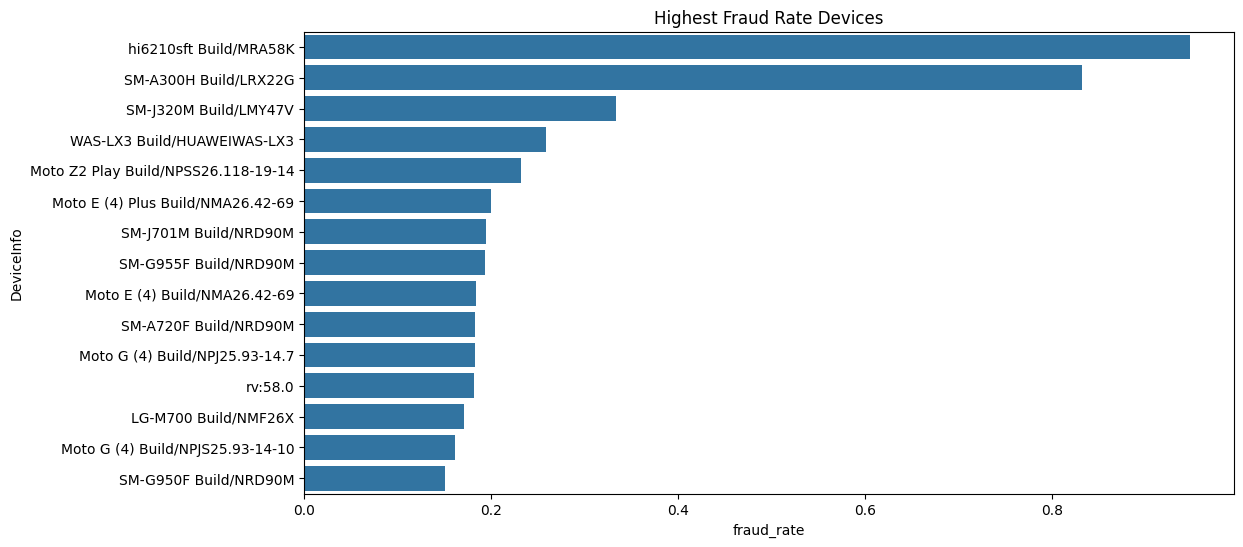

In [21]:
top_devices = (
    device_stats
    .sort_values("fraud_rate", ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))
sns.barplot(
    x=top_devices["fraud_rate"],
    y=top_devices.index
)
plt.title("Highest Fraud Rate Devices")
plt.show()

Correlation Analysis

In [22]:
numeric_cols = ieee_df.select_dtypes(
    include=np.number
).columns

numeric_cols = [
    c for c in numeric_cols
    if c not in ["TransactionID","isFraud"]
]

corr_with_target = (
    ieee_df[numeric_cols]
    .corrwith(ieee_df["isFraud"])
    .sort_values(ascending=False)
)

print(corr_with_target.head(20))

V257    0.383060
V246    0.366878
V244    0.364129
V242    0.360590
V201    0.328005
V200    0.318783
V189    0.308219
V188    0.303582
V258    0.297151
V45     0.281832
V158    0.278066
V156    0.275952
V149    0.273282
V228    0.268861
V44     0.260376
V86     0.251828
V87     0.251737
V170    0.249794
V147    0.242894
V52     0.239469
dtype: float64


In [23]:
corr_with_target = (ieee_df[numeric_cols].corrwith(ieee_df["isFraud"]).sort_values(ascending=False))

print(corr_with_target.head(20))

V257    0.383060
V246    0.366878
V244    0.364129
V242    0.360590
V201    0.328005
V200    0.318783
V189    0.308219
V188    0.303582
V258    0.297151
V45     0.281832
V158    0.278066
V156    0.275952
V149    0.273282
V228    0.268861
V44     0.260376
V86     0.251828
V87     0.251737
V170    0.249794
V147    0.242894
V52     0.239469
dtype: float64


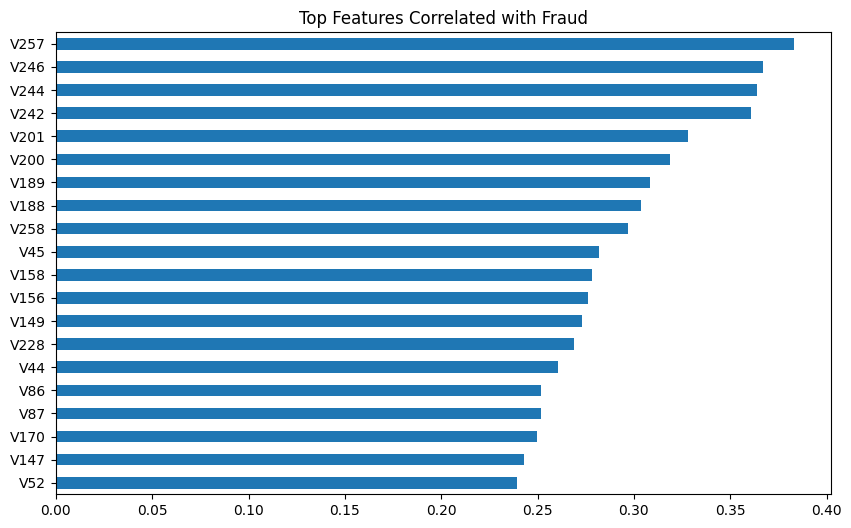

In [24]:
top_corr = corr_with_target.abs().sort_values(ascending=False).head(20)

plt.figure(figsize=(10,6))
top_corr.sort_values().plot(kind="barh")
plt.title("Top Features Correlated with Fraud")
plt.show()

Now Handle Missing Values

In [25]:
import gc

num_cols = [
    col for col in ieee_df.columns
    if ieee_df[col].dtype.kind in "if"
]

for col in num_cols:
    ieee_df[col] = ieee_df[col].fillna(
        ieee_df[col].median()
    )

gc.collect()

print("Numerical imputation complete")

Numerical imputation complete


In [26]:
important_missing_cols = [
    "DeviceInfo",
    "DeviceType",
    "id_31",
    "id_33"
]

for col in important_missing_cols:
    ieee_df[f"{col}_missing"] = (
        ieee_df[col].isnull()
        .astype(np.int8)
    )

In [27]:
cat_cols = ieee_df.select_dtypes(include=["object"]).columns

for col in cat_cols:
    ieee_df[col] = ieee_df[col].fillna(
        "Missing"
    )
    

In [28]:
ieee_df.isnull().sum()

TransactionID         0
isFraud               0
TransactionDT         0
TransactionAmt        0
ProductCD             0
                     ..
Day                   0
LogAmt                0
DeviceType_missing    0
id_31_missing         0
id_33_missing         0
Length: 440, dtype: int64

Feature Importance

In [29]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [30]:
model_df = ieee_df.copy()

for col in model_df.select_dtypes(include="object"):
    model_df[col] = LabelEncoder().fit_transform(
        model_df[col].astype(str)
    )

X = model_df.drop(
    columns=["isFraud"]
)

y = model_df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [31]:
# Redundant cell cleared to save memory and avoid duplication
print("Cell 47 cleared: LightGBM preprocessing was fixed in Cell 46.")


Cell 47 cleared: LightGBM preprocessing was fixed in Cell 46.


In [32]:
model = LGBMClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 16530, number of negative: 455902
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.324785 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 39322
[LightGBM] [Info] Number of data points in the train set: 472432, number of used features: 437
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.034989 -> initscore=-3.317101
[LightGBM] [Info] Start training from score -3.317101


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [33]:
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

importance_df.head()

,feature,importance
2,TransactionAmt,127
4,card1,120
5,card2,116
10,addr1,95
28,C13,81


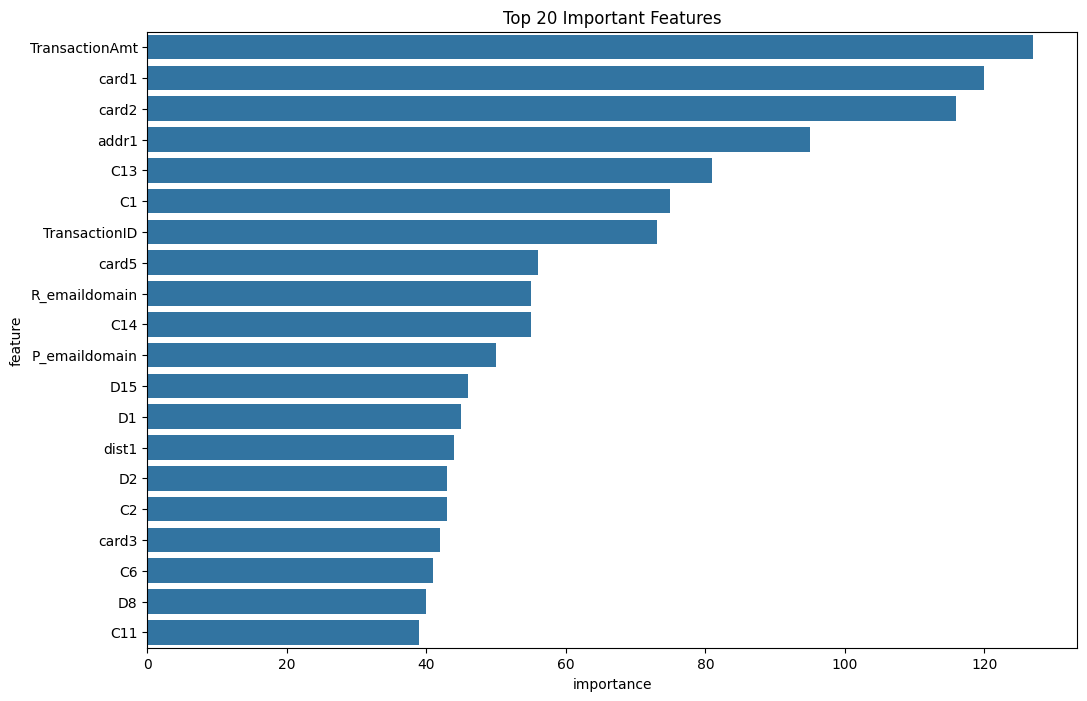

In [34]:
plt.figure(figsize=(12,8))

sns.barplot(
    x="importance",
    y="feature",
    data=importance_df.head(20)
)

plt.title("Top 20 Important Features")
plt.show()

Dataset Summary Table

In [35]:
summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Fraud Rate %",
        "Numeric Features",
        "Categorical Features",
        "DeviceInfo Missing %"
    ],
    "Value": [
        ieee_df.shape[0],
        ieee_df.shape[1],
        round(
            ieee_df["isFraud"].mean()*100,
            2
        ),
        len(
            ieee_df.select_dtypes(
                include=["number"]
            ).columns
        ),
        len(
            ieee_df.select_dtypes(
                include=["object"]
            ).columns
        ),
        round(
            ieee_df["DeviceInfo"].isnull().mean()*100,
            2
        )
    ]
})

summary


,Metric,Value
0,Rows,590540.0
1,Columns,440.0
2,Fraud Rate %,3.5
3,Numeric Features,409.0
4,Categorical Features,31.0
5,DeviceInfo Missing %,0.0


In [36]:
import gc

ieee_df.to_parquet(
    "processed_ieee.parquet",
    compression="snappy",
    index=False
)

print("Saved")

gc.collect()

Saved


13589